In [21]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

In [22]:
df_raw = pd.read_csv("Cars Datasets 2025.csv", encoding="latin1")

print(f"Initial Dataset Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print("\nColumn Names & Data Types:")
print(df_raw.dtypes)
print("\nFirst 5 Sample Records:")
display(df_raw.head())

Initial Dataset Shape: 1218 rows x 11 columns

Column Names & Data Types:
Company Names                object
Cars Names                   object
Engines                      object
CC/Battery Capacity          object
HorsePower                   object
Total Speed                  object
Performance(0 - 100 )KM/H    object
Cars Prices                  object
Fuel Types                   object
Seats                        object
Torque                       object
dtype: object

First 5 Sample Records:


,Company Names,Cars Names,Engines,CC/Battery Capacity,HorsePower,Total Speed,Performance(0 - 100 )KM/H,Cars Prices,Fuel Types,Seats,Torque
0,FERRARI,SF90 STRADALE,V8,3990 cc,963 hp,340 km/h,2.5 sec,"$1,100,000",plug in hyrbrid,2,800 Nm
1,ROLLS ROYCE,PHANTOM,V12,6749 cc,563 hp,250 km/h,5.3 sec,"$460,000",Petrol,5,900 Nm
2,Ford,KA+,1.2L Petrol,"1,200 cc",70-85 hp,165 km/h,10.5 sec,"$12,000-$15,000",Petrol,5,100 - 140 Nm
3,MERCEDES,GT 63 S,V8,"3,982 cc",630 hp,250 km/h,3.2 sec,"$161,000",Petrol,4,900 Nm
4,AUDI,AUDI R8 Gt,V10,"5,204 cc",602 hp,320 km/h,3.6 sec,"$253,290",Petrol,2,560 Nm


In [23]:
print("\nMissing Values per Column:")
print(df_raw.isnull().sum())
print(f"\nExact Duplicate Rows: {df_raw.duplicated().sum()}")


Missing Values per Column:
Company Names                0
Cars Names                   0
Engines                      0
CC/Battery Capacity          3
HorsePower                   0
Total Speed                  0
Performance(0 - 100 )KM/H    6
Cars Prices                  0
Fuel Types                   0
Seats                        0
Torque                       1
dtype: int64

Exact Duplicate Rows: 4


In [24]:
df = df_raw.copy()

In [25]:
df = df.drop_duplicates().reset_index(drop=True)

In [26]:
df["Company_Clean"] = df["Company Names"].str.strip().str.upper()

def standardize_fuel(val):
    s = str(val).strip().lower()
    if "plug" in s:
        return "Plug-in Hybrid"
    elif "hybrid" in s or "petrol/ev" in s:
        return "Hybrid"
    elif "electric" in s or s == "ev":
        return "Electric"
    elif "hydrogen" in s:
        return "Hydrogen"
    elif "diesel" in s and "petrol" in s:
        return "Petrol/Diesel"
    elif "diesel" in s:
        return "Diesel"
    elif "petrol" in s:
        return "Petrol"
    return "Other"

df["Fuel_Category"] = df["Fuel Types"].apply(standardize_fuel)

In [27]:
def parse_numeric_mean(val):
    if pd.isna(val):
        return np.nan
    s = str(val).replace(",", "").strip()
    nums = re.findall(r"\d+\.?\d*", s)
    if not nums:
        return np.nan
    return float(np.mean([float(x) for x in nums]))

df["HorsePower_HP"] = df["HorsePower"].apply(parse_numeric_mean)
df["Top_Speed_KMH"] = df["Total Speed"].apply(parse_numeric_mean)
df["Accel_0_100_Sec"] = df["Performance(0 - 100 )KM/H"].apply(parse_numeric_mean)
df["Price_USD"] = df["Cars Prices"].apply(parse_numeric_mean)
df["Torque_Nm"] = df["Torque"].apply(parse_numeric_mean)

In [28]:
def parse_cc(val):
    if pd.isna(val):
        return np.nan
    s = str(val).lower().replace(",", "").strip()
    if "kwh" in s:
        return np.nan
    nums = re.findall(r"\d+\.?\d*", s)
    return float(np.mean([float(x) for x in nums])) if nums else np.nan

df["Engine_CC"] = df["CC/Battery Capacity"].apply(parse_cc)

In [29]:
def parse_seats(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if "+" in s:
        parts = re.findall(r"\d+", s)
        return float(sum(int(p) for p in parts)) if parts else np.nan
    nums = re.findall(r"\d+", s)
    return float(nums[0]) if nums else np.nan

df["Seats_Clean"] = df["Seats"].apply(parse_seats)

In [30]:
df = df.dropna(subset=["Price_USD"]).reset_index(drop=True)

print(f"\nCleaned Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns")



Cleaned Dataset Shape: 1213 rows x 20 columns


In [31]:
num_cols = ["Price_USD", "HorsePower_HP", "Top_Speed_KMH", "Accel_0_100_Sec", "Torque_Nm", "Engine_CC", "Seats_Clean"]
print("\nDescriptive Statistics (Numerical Features):")
display(df[num_cols].describe().round(2))

print("\nTop 10 Manufacturers by Model Count:")
print(df["Company_Clean"].value_counts().head(10))

print("\nFuel Type Distribution:")
print(df["Fuel_Category"].value_counts())


Descriptive Statistics (Numerical Features):


,Price_USD,HorsePower_HP,Top_Speed_KMH,Accel_0_100_Sec,Torque_Nm,Engine_CC,Seats_Clean
count,1213.00,1213.00,1213.00,1208.00,1213.00,1099.00,1213.00
mean,138382.42,307.74,216.51,7.56,507.67,2964.71,4.84
std,712188.39,222.98,53.02,3.32,1051.12,1846.22,1.51
min,4000.00,26.00,80.00,1.90,45.00,360.00,1.00
25%,28000.00,153.00,180.00,5.20,250.00,1598.00,4.00
50%,42795.00,255.00,200.00,7.10,370.00,2480.00,5.00
75%,70000.00,400.00,250.00,9.50,560.00,3696.00,5.00
max,18000000.00,2488.00,500.00,35.00,15590.00,16100.00,20.00



Top 10 Manufacturers by Model Count:
Company_Clean
NISSAN        159
VOLKSWAGEN    107
PORSCHE        96
MAZDA          86
KIA            71
MITSUBISHI     60
GMC            59
CHEVROLET      57
PEUGEOT        54
FORD           54
Name: count, dtype: int64

Fuel Type Distribution:
Fuel_Category
Petrol            872
Diesel            106
Hybrid            106
Electric           96
Petrol/Diesel      23
Plug-in Hybrid      7
Hydrogen            3
Name: count, dtype: int64


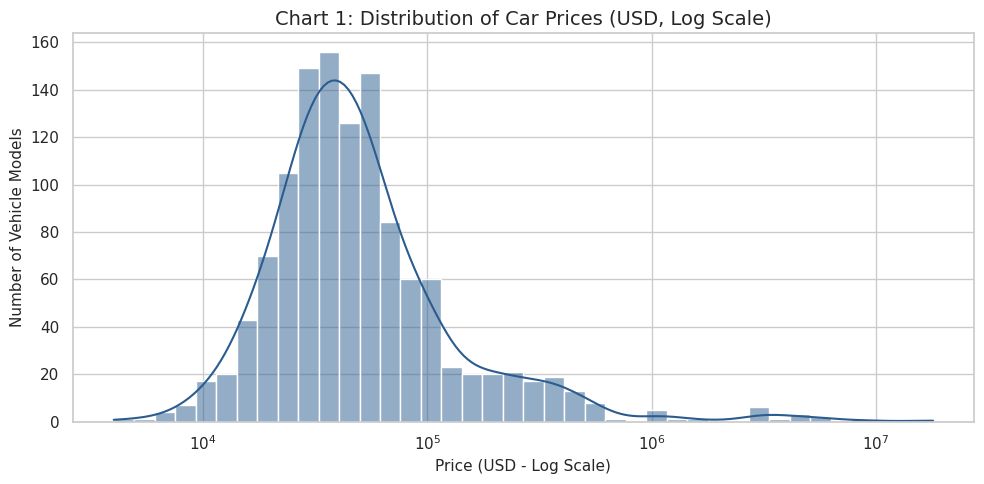

In [32]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Price_USD"], bins=40, kde=True, color="#2b5c8f", log_scale=True)
plt.title("Chart 1: Distribution of Car Prices (USD, Log Scale)")
plt.xlabel("Price (USD - Log Scale)")
plt.ylabel("Number of Vehicle Models")
plt.tight_layout()
plt.show()


/tmp/ipykernel_1265/2924384889.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_brands.values, y=top_brands.index, palette="viridis")


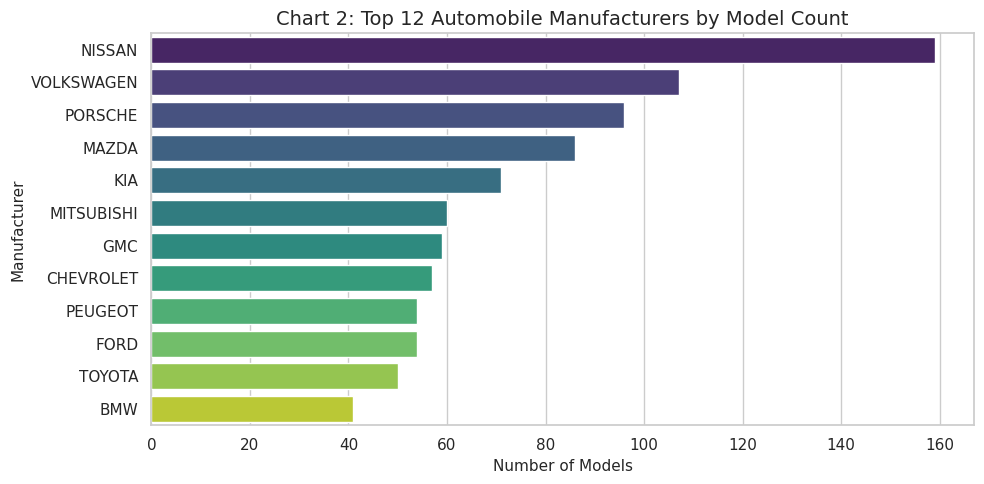

In [33]:
top_brands = df["Company_Clean"].value_counts().head(12)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_brands.values, y=top_brands.index, palette="viridis")
plt.title("Chart 2: Top 12 Automobile Manufacturers by Model Count")
plt.xlabel("Number of Models")
plt.ylabel("Manufacturer")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1265/1025384761.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Fuel_Category", order=fuel_order, palette="Set2")


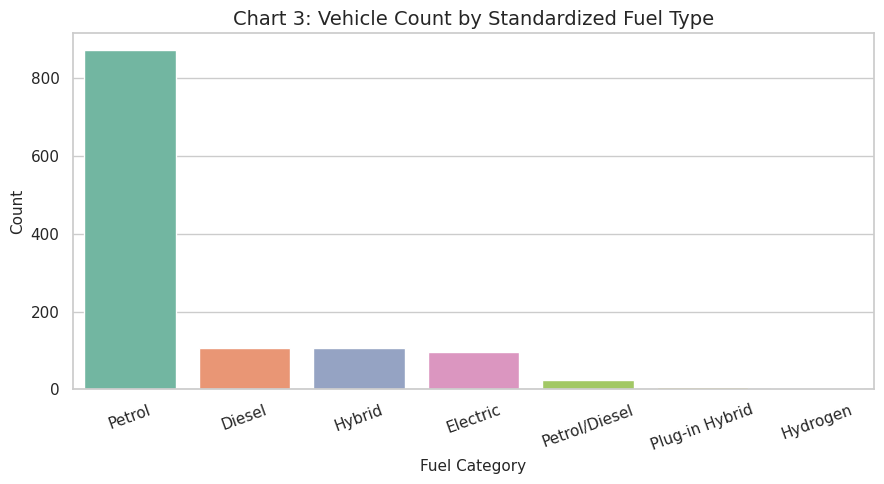

In [34]:
plt.figure(figsize=(9, 5))
fuel_order = df["Fuel_Category"].value_counts().index
sns.countplot(data=df, x="Fuel_Category", order=fuel_order, palette="Set2")
plt.title("Chart 3: Vehicle Count by Standardized Fuel Type")
plt.xlabel("Fuel Category")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1265/2463866084.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Fuel_Category", y="Price_USD", order=fuel_order, palette="pastel")


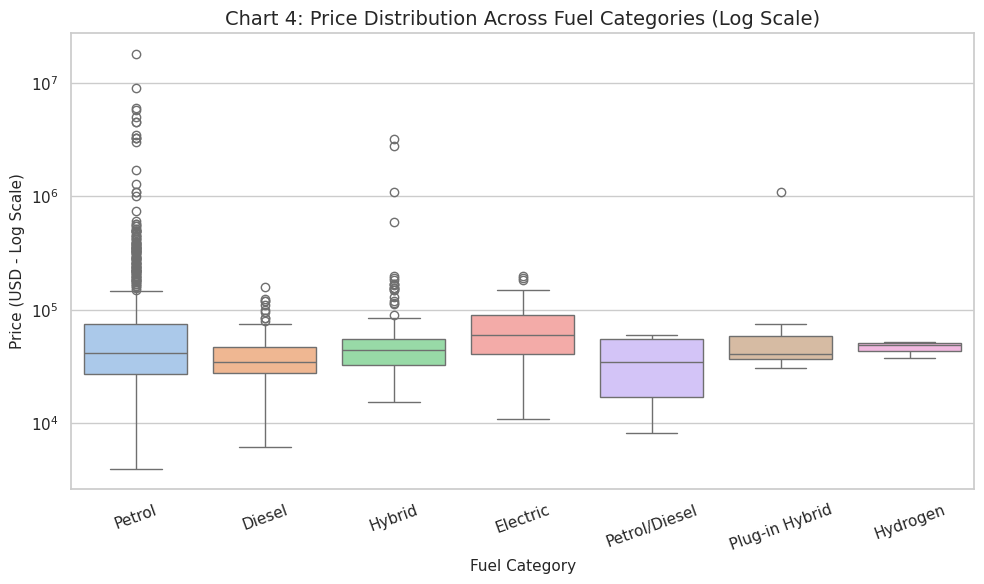

In [35]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Fuel_Category", y="Price_USD", order=fuel_order, palette="pastel")
plt.yscale("log")
plt.title("Chart 4: Price Distribution Across Fuel Categories (Log Scale)")
plt.xlabel("Fuel Category")
plt.ylabel("Price (USD - Log Scale)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

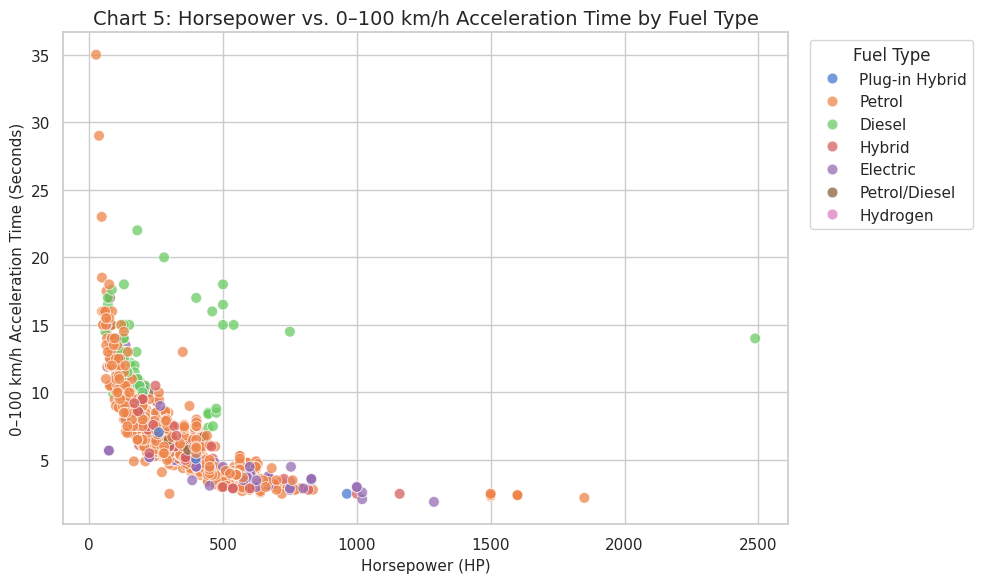

In [36]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="HorsePower_HP",
    y="Accel_0_100_Sec",
    hue="Fuel_Category",
    alpha=0.75,
    s=60
)
plt.title("Chart 5: Horsepower vs. 0–100 km/h Acceleration Time by Fuel Type")
plt.xlabel("Horsepower (HP)")
plt.ylabel("0–100 km/h Acceleration Time (Seconds)")
plt.legend(title="Fuel Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

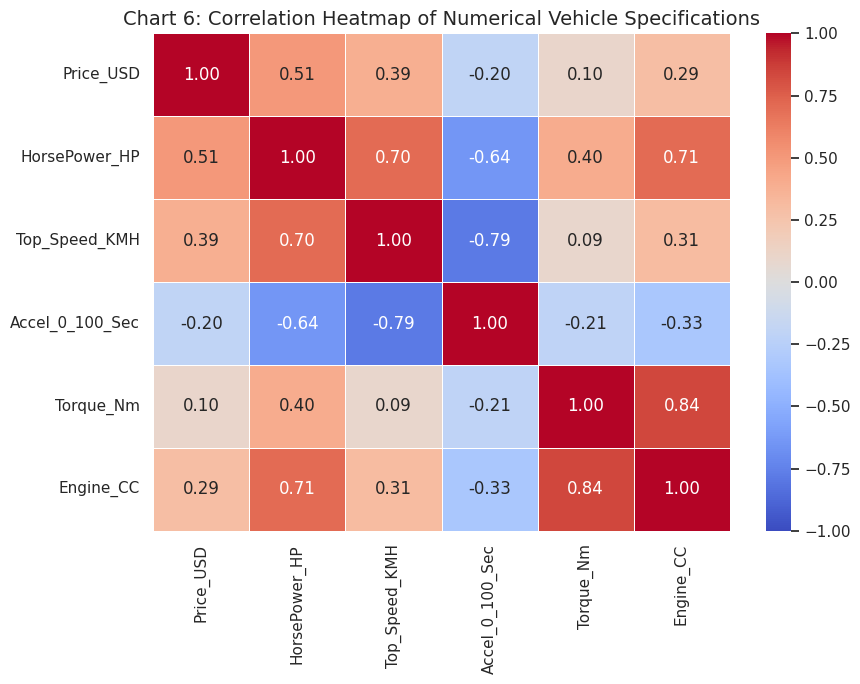

In [37]:
corr_cols = ["Price_USD", "HorsePower_HP", "Top_Speed_KMH", "Accel_0_100_Sec", "Torque_Nm", "Engine_CC"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Chart 6: Correlation Heatmap of Numerical Vehicle Specifications")
plt.tight_layout()
plt.show()

In [38]:
print("\nMedian Price & Horsepower by Fuel Category:")
display(df.groupby("Fuel_Category")[["Price_USD", "HorsePower_HP", "Accel_0_100_Sec"]].median().round(2))

print("\nTop 10 Most Expensive Brands (Median Price):")
display(df.groupby("Company_Clean")["Price_USD"].agg(["count", "median", "mean"]).sort_values(by="median", ascending=False).head(10).round(2))


Median Price & Horsepower by Fuel Category:


,Price_USD,HorsePower_HP,Accel_0_100_Sec
Fuel_Category,,,
Diesel,35000.0,167.5,11.00
Electric,59997.5,360.5,5.10
Hybrid,44075.0,227.0,7.50
Hydrogen,49500.0,152.0,9.00
Petrol,42050.0,276.0,6.80
Petrol/Diesel,35000.0,187.0,10.00
Plug-in Hybrid,41000.0,261.0,7.05



Top 10 Most Expensive Brands (Median Price):


,count,median,mean
Company_Clean,,,
BUGATTI,10,4000000.0,5870000.00
ROLLS ROYCE,30,377500.0,390400.00
LAMBORGHINI,24,334500.0,650083.33
BENTLEY,1,311000.0,311000.00
ASTON MARTIN,11,294000.0,752949.09
FERRARI,9,280000.0,512222.22
PORSCHE,96,113300.0,138389.58
VOLVO,12,97500.0,97083.33
TESLA,10,79195.0,87032.00
